# 10 - Forecast of daily PM2.5 one to three days ahead, issued at 17:00 KST

**Question.** How well can Seoul's daily PM2.5 be forecast for the next three days with the information available when the Korean forecast is announced (17:00 KST), and what do regional data and weather forecasts add?

**Protocol.**
- **Target**: the city daily PM2.5 of day D+1, D+2 and D+3 (mean of the daily means of the 25 urban stations), issued at 17:00 KST of day D. A Bad-or-worse day is `is_bad` (rounded mean above 35 ug/m3), the rule of the Korean grade.
- **No information from after the issue time**: hourly pollution, Baengnyeong and observed weather up to the hour 15:00-16:00 of D (one hour of margin for publication); archived JMA weather forecasts made at least one day earlier; CAMS up to 08:00 of D. Section 1 shows the check.
- **Time-ordered evaluation**: one origin per year. Each year is forecast by models fit only on rows whose target day is before 1 January of that year. Validation years 2020-2021 choose the inputs, the model, its settings and the alert threshold; 2022-2025 are the test years, scored once with those choices. Models using JMA forecasts are fit from 2019, the first year with every variable archived.
- **References**: persistence (the mean of the last 24 hours at issue time) and climatology (the mean of the training years within 15 days of the target's day of year). Skill = 1 - MAE / MAE of the reference, with 95% intervals that resample whole weeks.

Notebook 05 is the earlier next-day forecast on the Kaggle data of 2017-2019 per district; this notebook replaces it for the city forecast on the official data of 2015-2025.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from seoul_air import config, multiday as md, nwp, regional
from seoul_air.metrics import is_bad, paired_block_bootstrap
from seoul_air.report import save_key_figures

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 1. Inputs and the issue-time rule

In [2]:
air = pd.read_parquet(config.DATA_PROCESSED / "air_hourly_2015_2025.parquet",
                      columns=["datetime", "pm25", "pm10", "no2", "o3", "co"])
city = md.hourly_grid(air.groupby("datetime").mean())
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet", columns=["date", "pm25"])
city_daily = daily.groupby("date")["pm25"].mean()
city_daily.index = pd.DatetimeIndex(city_daily.index)

background_all = regional.load_background(2015, 2025)
baengnyeong = background_all[background_all["code"] == regional.BAENGNYEONG].set_index("datetime")[["pm25", "pm10"]]
baengnyeong = md.hourly_grid(baengnyeong)
weather_hourly = md.hourly_grid(pd.read_parquet(config.DATA_PROCESSED / "weather_hourly_2015_2025.parquet").set_index("datetime"))
nwp_daily = nwp.daily_forecasts(nwp.download())
cams = md.hourly_grid(regional.read_cams(regional.download_cams()))

issue_dates = pd.date_range("2015-01-08", "2025-12-30", freq="D")
features_at_issue = (md.air_features(city, issue_dates)
                     .join(md.background_features(baengnyeong, issue_dates))
                     .join(md.observed_weather_features(weather_hourly, issue_dates))
                     .join(md.cams_features(cams, issue_dates)))
tables = md.build_tables(city_daily, features_at_issue, nwp_daily)
AIR = [c for c in features_at_issue.columns if not c.startswith(("bg_", "obs_", "cams_"))]
BG = [c for c in features_at_issue.columns if c.startswith("bg_")]
OBS = [c for c in features_at_issue.columns if c.startswith("obs_")]
CAMS = [c for c in features_at_issue.columns if c.startswith("cams_")]
CAL = ["target_doy_sin", "target_doy_cos", "target_weekday"]
NWP = [c for c in tables[1].columns if c.startswith("nwp_")]

availability = pd.DataFrame({
    "inputs": [len(AIR), len(OBS), len(BG), len(NWP), len(CAMS)],
    "first day with a value": [features_at_issue[AIR].dropna(how="all").index.min().date(),
                               features_at_issue[OBS].dropna(how="all").index.min().date(),
                               features_at_issue[BG].dropna(how="all").index.min().date(),
                               nwp_daily[1].dropna(how="all").index.min().date(),
                               features_at_issue[CAMS].dropna(how="all").index.min().date()],
    "known at 17:00 because": ["hourly readings up to 15:00-16:00", "ERA5 up to 15:00-16:00 (stand-in for observations)",
                               "AirKorea final data up to 15:00-16:00 (stand-in for real-time)",
                               "JMA runs made at least 24 h before the start of the target day",
                               "CAMS up to 08:00 (runs started by 12 UTC of the day before)"],
}, index=["pollution (city)", "observed weather", "Baengnyeong", "JMA forecast (target day)", "CAMS upwind"])
print(availability.to_string())
print()
print("Issue days:", len(issue_dates), "| rows with a target, by horizon:", {h: int(t["target"].notna().sum()) for h, t in tables.items()})
print("Climatology window: +/-", 15, "days of the day of year | persistence: mean of the last", 24, "hours at issue")
print("JMA forecast days with every variable, by horizon:",
      {h: str(nwp_daily[h].dropna().index.min().date()) for h in md.HORIZONS})

                           inputs first day with a value                                          known at 17:00 because
pollution (city)               13             2015-01-08                               hourly readings up to 15:00-16:00
observed weather                8             2015-01-08              ERA5 up to 15:00-16:00 (stand-in for observations)
Baengnyeong                     5             2015-01-08  AirKorea final data up to 15:00-16:00 (stand-in for real-time)
JMA forecast (target day)      10             2018-01-01  JMA runs made at least 24 h before the start of the target day
CAMS upwind                    10             2022-08-05     CAMS up to 08:00 (runs started by 12 UTC of the day before)

Issue days: 4010 | rows with a target, by horizon: {1: 4010, 2: 4009, 3: 4008}
Climatology window: +/- 15 days of the day of year | persistence: mean of the last 24 hours at issue
JMA forecast days with every variable, by horizon: {1: '2018-01-01', 2: '2019-01-05', 3: '201

The check: values after 15:00-16:00 of an issue day are replaced by an impossible value; the features of that day must not change, while those of the next day do.

In [3]:
day = pd.Timestamp("2024-03-01")
changed = city.copy()
changed.loc[day + pd.Timedelta(hours=16):, :] = 999.0
before = md.air_features(city, [day, day + pd.Timedelta(days=1)])
after = md.air_features(changed, [day, day + pd.Timedelta(days=1)])
print("Features of the issue day unchanged:", bool(np.allclose(before.iloc[0], after.iloc[0], equal_nan=True)))
print("Features of the next issue day changed:", not bool(np.allclose(before.iloc[1], after.iloc[1], equal_nan=True)))
changed_weather = weather_hourly.copy()
changed_weather.loc[day + pd.Timedelta(hours=16):, :] = 999.0
print("Observed weather of the issue day unchanged:", bool(np.allclose(
    md.observed_weather_features(weather_hourly, [day]).iloc[0], md.observed_weather_features(changed_weather, [day]).iloc[0], equal_nan=True)))

Features of the issue day unchanged: True
Features of the next issue day changed: True
Observed weather of the issue day unchanged: True


**Interpretation.** Pollution, observed weather and Baengnyeong are available from 2015; the JMA forecast from 2018 for D+1 and from January 2019 for D+2 and D+3, the first days with every variable; CAMS only from August 2022. All 4010 issue days have the 24-hour mean needed for persistence, so no day is left out. The check confirms the rule: an impossible value placed after 15:00-16:00 does not change the features of that issue day, but does change those of the next one. Two inputs are stand-ins for what an operational forecaster would see: ERA5 for the real-time weather observations and the AirKorea final data for the real-time Baengnyeong readings; both are close to, but not identical with, the values published in real time.

## 2. Validation: inputs, model and settings

Three sets of inputs are compared, each adding one source: pollution and observed weather up to the issue time with the calendar of the target day; plus Baengnyeong; plus the JMA forecast of the target day. Each is fit with a ridge regression on log PM2.5 (three penalties) and with gradient boosting (two sizes). All are scored on the validation years 2020-2021, the years every set can forecast; the lowest MAE chooses the forecast of each horizon.

In [4]:
VALIDATION = md.yearly_origins([2020, 2021])
TEST = md.yearly_origins(range(2022, 2026))
NWP_START = "2019-01-01"
SETS = {
    "pollution + observed weather": (AIR + OBS + CAL, None),
    "+ Baengnyeong": (AIR + OBS + CAL + BG, None),
    "+ Baengnyeong + JMA forecast": (AIR + OBS + CAL + BG + NWP, NWP_START),
}
MODELS = {
    "ridge, alpha 1": lambda: md.make_ridge(1.0),
    "ridge, alpha 10": lambda: md.make_ridge(10.0),
    "ridge, alpha 100": lambda: md.make_ridge(100.0),
    "boosting, small": lambda: md.make_hgb(max_leaf_nodes=7, min_samples_leaf=50),
    "boosting, larger": lambda: md.make_hgb(max_leaf_nodes=31, min_samples_leaf=20),
}


def forecast(table, columns, model, origins, train_start):
    def fit_predict(train, test):
        fitted = MODELS[model]().fit(train[columns], train["target"])
        return pd.DataFrame({"forecast": fitted.predict(test[columns]), "target": test["target"]}, index=test.index)
    return md.rolling_origins(table, origins, fit_predict, train_start=train_start)


def references(table, origins):
    table = table.dropna(subset=["pm25_24h"])  # persistence needs the last 24 hours

    def fit_predict(train, test):
        return pd.DataFrame({"persistence": test["pm25_24h"], "target": test["target"],
                             "climatology": md.climatology(train["target_date"], train["target"], test["target_date"])},
                            index=test.index)
    return md.rolling_origins(table, origins, fit_predict)


rows = []
for h in md.HORIZONS:
    ref = references(tables[h], VALIDATION)
    rows.append({"horizon": h, "inputs": "reference", "model": "persistence", "mae": md.scores(ref["target"], ref["persistence"])["mae"]})
    rows.append({"horizon": h, "inputs": "reference", "model": "climatology", "mae": md.scores(ref["target"], ref["climatology"])["mae"]})
    for set_name, (columns, start) in SETS.items():
        for model in MODELS:
            pred = forecast(tables[h], columns, model, VALIDATION, start)
            rows.append({"horizon": h, "inputs": set_name, "model": model, "mae": md.scores(pred["target"], pred["forecast"])["mae"]})
validation = pd.DataFrame(rows)
print("Issue days without a 24-hour mean at issue time (left out of every score):",
      {h: int(t["pm25_24h"].isna().sum()) for h, t in tables.items()})
print(validation.pivot_table(index=["inputs", "model"], columns="horizon", values="mae").round(2).to_string())
candidates = validation[validation["inputs"] != "reference"]
chosen = candidates.loc[candidates.groupby("horizon")["mae"].idxmin()].set_index("horizon")
print()
print("Chosen on validation:")
print(chosen.round(2).to_string())

Issue days without a 24-hour mean at issue time (left out of every score): {1: 0, 2: 0, 3: 0}
horizon                                           1      2      3
inputs                       model                               
+ Baengnyeong                boosting, larger  6.87   9.43   9.72
                             boosting, small   6.77   9.16   9.50
                             ridge, alpha 1    6.41   8.50   8.64
                             ridge, alpha 10   6.40   8.50   8.64
                             ridge, alpha 100  6.43   8.54   8.68
+ Baengnyeong + JMA forecast boosting, larger  6.04   8.07   8.33
                             boosting, small   6.16   7.96   8.56
                             ridge, alpha 1    5.27   6.63   7.01
                             ridge, alpha 10   5.12   6.56   6.89
                             ridge, alpha 100  5.34   6.74   7.01
pollution + observed weather boosting, larger  6.78   9.23   9.69
                             boosting, small   6

**Interpretation.** The JMA forecast of the target day is the input that matters: with it, the validation MAE falls to 5.12, 6.56 and 6.89 ug/m3 at D+1, D+2 and D+3 (ridge, alpha 10), against 6.40, 8.50 and 8.64 for the best model without it. Baengnyeong changes the MAE by a few hundredths. The ridge regression on log PM2.5 beats gradient boosting with every input set; with only the years since 2019 to fit the models with JMA inputs, a smooth model generalises better than trees. The references are far behind: persistence 9.66, 12.13 and 12.59, climatology 9.70 to 9.72. The ridge regression with alpha 10 and all three sources is chosen for every horizon.

## 3. Test, 2022-2025

The chosen forecast of each horizon, fit again at each yearly origin, against the two references. The other input sets are also scored with the chosen model type, to show what each source adds on years not used for any choice.

In [5]:
test_predictions = {}
test_rows = []
for h in md.HORIZONS:
    ref = references(tables[h], TEST)
    best = chosen.loc[h]
    pred = forecast(tables[h], SETS[best["inputs"]][0], best["model"], TEST, SETS[best["inputs"]][1])
    frame = ref.join(pred[["forecast"]], how="inner")
    test_predictions[h] = frame
    for name in ["persistence", "climatology", "forecast"]:
        test_rows.append({"horizon": h, "forecast": name if name != "forecast" else f"chosen: {best['model']}, {best['inputs']}",
                          **md.scores(frame["target"], frame[name])})
    for set_name, (columns, start) in SETS.items():
        if set_name != best["inputs"]:
            other = forecast(tables[h], columns, best["model"], TEST, start)
            test_rows.append({"horizon": h, "forecast": f"same model, {set_name}", **md.scores(other["target"], other["forecast"])})
test_scores = pd.DataFrame(test_rows).set_index(["horizon", "forecast"])
print(test_scores[["days", "mae", "rmse", "bias", "grade_accuracy"]].round(3).to_string())

                                                               days     mae    rmse   bias  grade_accuracy
horizon forecast                                                                                          
1       persistence                                            1460   8.464  11.867  0.001           0.575
        climatology                                            1460   9.062  11.409  3.910           0.518
        chosen: ridge, alpha 10, + Baengnyeong + JMA forecast  1460   5.078   7.366  0.077           0.734
        same model, pollution + observed weather               1460   6.141   8.677 -0.321           0.678
        same model, + Baengnyeong                              1460   6.036   8.498 -0.439           0.679
2       persistence                                            1459  10.553  14.398  0.001           0.496
        climatology                                            1459   9.063  11.412  3.908           0.517
        chosen: ridge, alpha 10, + Ba

In [6]:
skill_rows = []
for h, frame in test_predictions.items():
    weeks = frame.index.to_period("W")
    for reference in ["persistence", "climatology"]:
        draws = paired_block_bootstrap(frame["target"], frame["forecast"], frame[reference], weeks, n_boot=4000, seed=h)
        skill = 1 - md.scores(frame["target"], frame["forecast"])["mae"] / md.scores(frame["target"], frame[reference])["mae"]
        low, high = np.nanpercentile(draws["skill"], [2.5, 97.5])
        skill_rows.append({"horizon": h, "reference": reference, "skill_pct": 100 * skill,
                           "low_95_pct": 100 * low, "high_95_pct": 100 * high})
skill_table = pd.DataFrame(skill_rows).set_index(["horizon", "reference"])
print("MAE skill of the chosen forecast on 2022-2025 (95% interval, weekly blocks):")
print(skill_table.round(1).to_string())
by_year = pd.concat({h: frame.groupby(frame.index.year).apply(
    lambda part: pd.Series({name: md.scores(part["target"], part[name])["mae"] for name in ["persistence", "climatology", "forecast"]}))
    for h, frame in test_predictions.items()}, names=["horizon", "year"])
print()
print("MAE by test year (ug/m3):")
print(by_year.round(2).to_string())

MAE skill of the chosen forecast on 2022-2025 (95% interval, weekly blocks):
                     skill_pct  low_95_pct  high_95_pct
horizon reference                                      
1       persistence       40.0        36.6         43.0
        climatology       44.0        40.4         47.3
2       persistence       43.1        39.7         46.3
        climatology       33.8        29.4         37.9
3       persistence       43.9        40.6         47.1
        climatology       31.6        27.6         35.6

MAE by test year (ug/m3):
              persistence  climatology  forecast
horizon year                                    
1       2022         8.13         9.43      5.02
        2023         9.13         8.92      5.41
        2024         8.13         8.89      4.95
        2025         8.46         9.00      4.93
2       2022        10.38         9.47      5.88
        2023        11.30         8.87      6.25
        2024        10.01         8.92      5.79
       

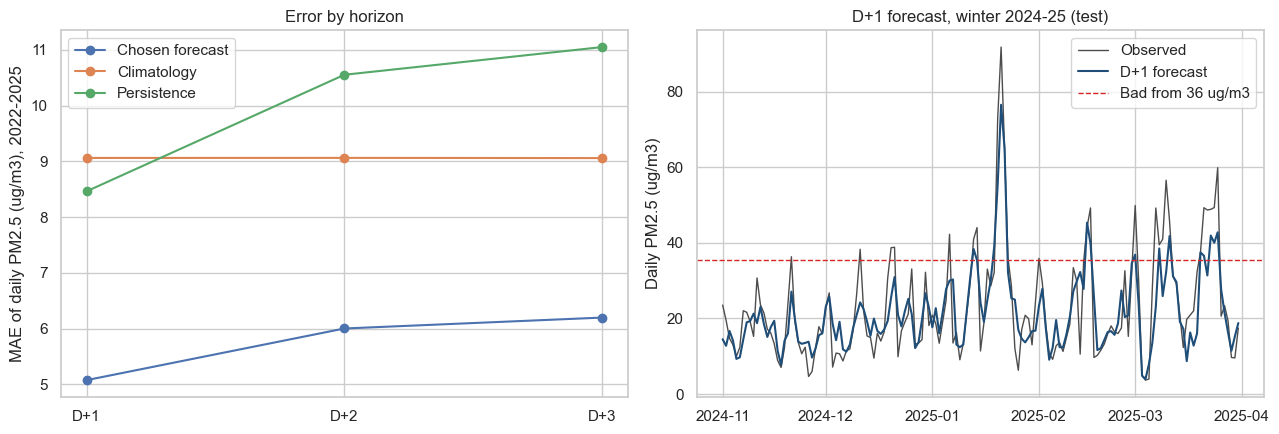

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
mae = test_scores["mae"].unstack("horizon")
labels = {"persistence": "Persistence", "climatology": "Climatology"}
for name in mae.index:
    if name in labels or name.startswith("chosen"):
        axes[0].plot(list(md.HORIZONS), mae.loc[name], marker="o", label=labels.get(name, "Chosen forecast"))
axes[0].set_xticks(list(md.HORIZONS), [f"D+{h}" for h in md.HORIZONS])
axes[0].set_ylabel("MAE of daily PM2.5 (ug/m3), 2022-2025")
axes[0].set_title("Error by horizon")
axes[0].legend()
frame = test_predictions[1].loc["2024-10-31":"2025-03-30"]
frame = frame.set_axis(frame.index + pd.Timedelta(days=1))  # plotted on the target day
axes[1].plot(frame.index, frame["target"], color="0.3", lw=1, label="Observed")
axes[1].plot(frame.index, frame["forecast"], color="#1f4e79", lw=1.5, label="D+1 forecast")
axes[1].axhline(35.5, color="#d62728", ls="--", lw=1, label="Bad from 36 ug/m3")
axes[1].set_ylabel("Daily PM2.5 (ug/m3)")
axes[1].set_title("D+1 forecast, winter 2024-25 (test)")
axes[1].legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "10_forecast_by_horizon.png", dpi=150)
plt.show()

**Interpretation.** On 2022-2025 the chosen forecast keeps its validation level: MAE 5.078, 6.004 and 6.200 ug/m3 at D+1, D+2 and D+3, against 8.464, 10.553 and 11.050 for persistence and about 9.06 for climatology. The skill against persistence is 40.0% at D+1 (95% interval 36.6% to 43.0%), 43.1% at D+2 and 43.9% at D+3; against climatology 44.0%, 33.8% and 31.6%, all with intervals far from zero. The share of days with the right grade is 0.734 at D+1, 0.666 at D+2 and 0.671 at D+3, against 0.575, 0.496 and 0.471 for persistence. The result holds in every test year (D+1 MAE between 4.93 and 5.41). Without the JMA inputs the same model has an MAE of 6.036, 7.580 and 7.860, so the weather forecast accounts for most of the gain at D+2 and D+3, where the pollution of the issue day says little. Climatology has a bias of +3.9 ug/m3 because it averages years when PM2.5 was higher; persistence has no bias but a large error. The forecast underestimates slightly at D+2 and D+3 (bias -0.682 and -0.879).

## 4. Quantile forecasts

Gradient boosting with the quantile loss gives the 10th, 50th and 90th percentiles of each target day, with the inputs chosen above. The interval between the 10th and 90th percentiles should contain the observed value on 80% of the days. Boosted quantiles are often too narrow, so the interval is also calibrated: both ends move out by the amount that would have given 80% coverage on the validation years (conformalised quantile regression, Romano et al. 2019), and that amount is then applied unchanged to the test years. The pinball loss scores each quantile; the reference is the same quantile of the climatology.

In [8]:
def quantile_forecasts(h, origins):
    columns, start = SETS[chosen.loc[h, "inputs"]]

    def fit_predict(train, test):
        out = {"target": test["target"]}
        for q in md.QUANTILES:
            model = md.make_hgb(loss="quantile", quantile=q, max_leaf_nodes=7, min_samples_leaf=50)
            out[f"q{int(q * 100)}"] = model.fit(train[columns], train["target"]).predict(test[columns])
            out[f"clim_q{int(q * 100)}"] = md.climatology(train["target_date"], train["target"], test["target_date"], quantile=q)
        return pd.DataFrame(out, index=test.index)
    return md.rolling_origins(tables[h], origins, fit_predict, train_start=start)


quantile_rows = []
quantile_test = {}
widening = {}
for h in md.HORIZONS:
    for period, origins in [("validation", VALIDATION), ("test", TEST)]:
        q = quantile_forecasts(h, origins)
        q[["q10", "q50", "q90"]] = np.sort(q[["q10", "q50", "q90"]].to_numpy(), axis=1)  # no crossing
        if period == "validation":
            widening[h] = md.conformal_widening(q["target"], q["q10"], q["q90"], coverage=0.8)
        q["q10_cal"], q["q90_cal"] = q["q10"] - widening[h], q["q90"] + widening[h]
        if period == "test":
            quantile_test[h] = q
        row = {"horizon": h, "period": period, **md.interval_scores(q["target"], q["q10"], q["q90"])}
        calibrated = md.interval_scores(q["target"], q["q10_cal"], q["q90_cal"])
        row["calibrated_coverage"], row["calibrated_width"] = calibrated["coverage"], calibrated["mean_width"]
        for p in (10, 50, 90):
            model_loss = md.pinball(q["target"], q[f"q{p}"], p / 100)
            row[f"pinball_skill_q{p}_pct"] = 100 * (1 - model_loss / md.pinball(q["target"], q[f"clim_q{p}"], p / 100))
        row["climatology_coverage"] = md.interval_scores(q["target"], q["clim_q10"], q["clim_q90"])["coverage"]
        quantile_rows.append(row)
quantile_scores = pd.DataFrame(quantile_rows).set_index(["horizon", "period"])
print("Interval: 10th to 90th percentile, nominal coverage", 80, "%")
print("Widening from the validation years (ug/m3 on each side):", {h: round(w, 2) for h, w in widening.items()})
print(quantile_scores.round(3).to_string())

Interval: 10th to 90th percentile, nominal coverage 80 %
Widening from the validation years (ug/m3 on each side): {1: 2.44, 2: 2.93, 3: 3.05}
                    nominal  coverage  mean_width  calibrated_coverage  calibrated_width  pinball_skill_q10_pct  pinball_skill_q50_pct  pinball_skill_q90_pct  climatology_coverage
horizon period                                                                                                                                                                     
1       validation      0.8     0.603      14.629                0.803            19.510                 25.650                 37.760                 41.360                 0.722
        test            0.8     0.664      13.643                0.850            18.524                 17.096                 35.530                 36.293                 0.784
2       validation      0.8     0.584      17.423                0.803            23.289                  6.669                 22.848    

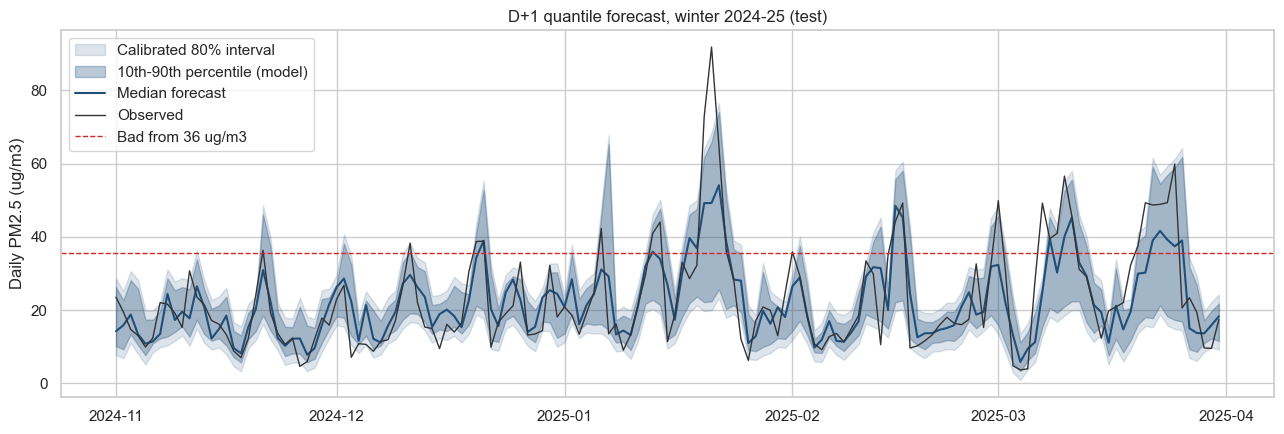

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
q = quantile_test[1].loc["2024-10-31":"2025-03-30"]
q = q.set_axis(q.index + pd.Timedelta(days=1))  # plotted on the target day
ax.fill_between(q.index, q["q10_cal"], q["q90_cal"], color="#1f4e79", alpha=0.15, label="Calibrated 80% interval")
ax.fill_between(q.index, q["q10"], q["q90"], color="#1f4e79", alpha=0.3, label="10th-90th percentile (model)")
ax.plot(q.index, q["q50"], color="#1f4e79", lw=1.5, label="Median forecast")
ax.plot(q.index, q["target"], color="0.2", lw=1, label="Observed")
ax.axhline(35.5, color="#d62728", ls="--", lw=1, label="Bad from 36 ug/m3")
ax.set_ylabel("Daily PM2.5 (ug/m3)")
ax.set_title("D+1 quantile forecast, winter 2024-25 (test)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(config.FIGURES / "10_quantiles.png", dpi=150)
plt.show()

**Interpretation.** The boosted quantiles are too narrow: the 10th-90th percentile interval contains 0.664 to 0.684 of the test days instead of 0.8. Moving both ends out by the amount found on the validation years (2.44, 2.93 and 3.05 ug/m3) gives 0.850, 0.860 and 0.859 on the test years, slightly above the nominal 0.8, with mean widths of 18.524, 22.459 and 23.848 ug/m3. Calibration on two years carries over to later years only approximately, but errs on the safe side here. The quantiles beat those of the climatology on every percentile: the pinball skill of the median is 35.530% at D+1, 22.399% at D+2 and 19.425% at D+3.

## 5. Bad-or-worse days

Four alerts for a Bad-or-worse day: persistence and the chosen point forecast with the grade rule; the 90th percentile above the Bad threshold (no tuning); and a gradient boosting classifier whose probability threshold maximises F1 on the validation years. POD is the share of Bad days with an alert, FAR the share of alerts on days that were not Bad, CSI = hits / (hits + misses + false alarms).

In [10]:
def classifier_probabilities(h, origins):
    columns, start = SETS[chosen.loc[h, "inputs"]]

    def fit_predict(train, test):
        model = md.make_classifier(max_leaf_nodes=7, min_samples_leaf=50)
        model.fit(train[columns], is_bad(train["target"]))
        return pd.DataFrame({"probability": model.predict_proba(test[columns])[:, 1], "target": test["target"]}, index=test.index)
    return md.rolling_origins(tables[h], origins, fit_predict, train_start=start)


alert_rows = []
thresholds = {}
for h in md.HORIZONS:
    val = classifier_probabilities(h, VALIDATION)
    thresholds[h] = round(md.best_probability_threshold(is_bad(val["target"]), val["probability"].to_numpy()), 2)
    test_prob = classifier_probabilities(h, TEST)
    frame = test_predictions[h].join(test_prob[["probability"]], how="inner").join(quantile_test[h][["q90"]], how="inner")
    alerts = {
        "persistence (grade rule)": is_bad(frame["persistence"]),
        "point forecast (grade rule)": is_bad(frame["forecast"]),
        "90th percentile above 35": is_bad(frame["q90"]),
        f"classifier (p >= {thresholds[h]:.2f})": frame["probability"].to_numpy() >= thresholds[h],
    }
    for name, flag in alerts.items():
        s = md.scores(frame["target"], frame["forecast"], alert=flag)
        alert_rows.append({"horizon": h, "alert": name, **{k: s[k] for k in ["bad_days", "alerts", "pod", "far", "csi", "f1"]}})
    test_predictions[h]["classifier_alert"] = alerts[f"classifier (p >= {thresholds[h]:.2f})"]
alert_table = pd.DataFrame(alert_rows).set_index(["horizon", "alert"])
print("Probability thresholds chosen on validation:", thresholds)
print(alert_table.round(3).to_string())

Probability thresholds chosen on validation: {1: 0.5, 2: 0.35, 3: 0.18}
                                     bad_days  alerts    pod    far    csi     f1
horizon alert                                                                    
1       persistence (grade rule)          122     123  0.352  0.650  0.213  0.351
        point forecast (grade rule)       122      75  0.418  0.320  0.349  0.518
        90th percentile above 35          122     225  0.779  0.578  0.377  0.548
        classifier (p >= 0.50)            122      98  0.516  0.357  0.401  0.573
2       persistence (grade rule)          122     123  0.189  0.813  0.104  0.188
        point forecast (grade rule)       122      64  0.311  0.406  0.257  0.409
        90th percentile above 35          122     269  0.680  0.691  0.269  0.425
        classifier (p >= 0.35)            122     127  0.443  0.575  0.277  0.434
3       persistence (grade rule)          122     123  0.123  0.878  0.065  0.122
        point forecast (gr

In [11]:
recall_rows = []
for h, frame in test_predictions.items():
    draws = paired_block_bootstrap(frame["target"], frame["forecast"], frame["persistence"], frame.index.to_period("W"),
                                   alert_a=frame["classifier_alert"], alert_b=is_bad(frame["persistence"]), n_boot=4000, seed=10 + h)
    low, high = np.nanpercentile(draws["recall_diff"], [2.5, 97.5])
    recall_rows.append({"horizon": h, "pod_difference_classifier_minus_persistence": draws["recall_diff"].median(),
                        "low_95": low, "high_95": high})
recall_table = pd.DataFrame(recall_rows).set_index("horizon")
print(recall_table.round(3).to_string())

         pod_difference_classifier_minus_persistence  low_95  high_95
horizon                                                              
1                                              0.167   0.065    0.264
2                                              0.259   0.130    0.372
3                                              0.469   0.350    0.588


**Interpretation.** The test years have 122 Bad-or-worse days. At D+1 the classifier with the validated threshold has a POD of 0.516 and a FAR of 0.357 (CSI 0.401), against 0.352 and 0.650 for persistence (CSI 0.213); the point forecast with the grade rule raises fewer alerts (POD 0.418, FAR 0.320), because a mean forecast rarely reaches the tails. The 90th percentile rule detects the most (POD 0.779) at the cost of more false alarms (FAR 0.578), a choice that suits a warning whose misses cost more than its false alarms. At D+2 and D+3 every alert is weaker (CSI at most 0.277), but persistence falls to a CSI of 0.104 and 0.065. The classifier detects 0.167 more of the Bad days than persistence at D+1 (95% interval 0.065 to 0.264), 0.259 more at D+2 and 0.469 more at D+3, where its validated threshold (0.18) is low and it raises many alerts. Which alert to use is a choice between misses and false alarms, not a single best answer.

## 6. CAMS

CAMS is archived only from August 2022 and without its forecasts at longer lead times, so it cannot enter the models above, which need years of history. It is tested as a correction: a ridge regression learns the error of the chosen D+1 forecast from CAMS PM2.5 and dust upwind (24 hours to 08:00 of the issue day), using only the days before each quarterly origin from 2023 (the first errors are those of September 2022).

In [12]:
cams_rows = []
for h in md.HORIZONS:
    base = test_predictions[h].join(tables[h][CAMS])
    base = base[base.index >= "2022-09-01"]
    base["error"] = base["target"] - base["forecast"]

    def fit_predict(train, test):
        model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        model.fit(train[CAMS], train["error"])
        return pd.DataFrame({"correction": model.predict(test[CAMS])}, index=test.index)
    table = base.assign(target_date=tables[h].loc[base.index, "target_date"])
    corrected = md.rolling_origins(table, md.quarterly_origins("2023-01-01", "2025-10-01"), fit_predict)
    rows_ = base.loc[corrected.index]
    with_cams = rows_["forecast"] + corrected["correction"]
    draws = paired_block_bootstrap(rows_["target"], with_cams, rows_["forecast"], rows_.index.to_period("W"), n_boot=4000, seed=20 + h)
    low, high = np.nanpercentile(draws["skill"], [2.5, 97.5])
    cams_rows.append({"horizon": h, "days": len(rows_), "mae_without": md.scores(rows_["target"], rows_["forecast"])["mae"],
                      "mae_with_cams": md.scores(rows_["target"], with_cams)["mae"],
                      "skill_pct": 100 * (1 - md.scores(rows_["target"], with_cams)["mae"] / md.scores(rows_["target"], rows_["forecast"])["mae"]),
                      "low_95_pct": 100 * low, "high_95_pct": 100 * high})
cams_table = pd.DataFrame(cams_rows).set_index("horizon")
print(cams_table.round(2).to_string())

         days  mae_without  mae_with_cams  skill_pct  low_95_pct  high_95_pct
horizon                                                                      
1        1095         5.10           5.28      -3.56       -6.37        -0.93
2        1094         6.05           6.32      -4.48       -6.94        -1.97
3        1093         6.26           6.61      -5.64       -8.18        -3.18


**Interpretation.** The CAMS correction makes the forecast worse at every horizon: the MAE rises from 5.10 to 5.28 ug/m3 at D+1 (skill -3.56%, 95% interval -6.37% to -0.93%), and by 4.48% and 5.64% at D+2 and D+3. With little more than three years of archive and no archived CAMS forecasts, CAMS upwind concentrations at issue time add nothing that the Seoul and Baengnyeong readings and the JMA forecast do not already carry, and the extra inputs add noise. This is a statement about the archived analysis used here; CAMS forecasts of the target days, which are not archived, could behave differently.

## 7. Comparison with published forecasts

Only one study reports Seoul daily PM2.5 forecasts with the same four grades: Lee et al. (2022, Geosci. Model Dev. 15, 3797-3813; doi:10.5194/gmd-15-3797-2022). It gives the accuracy of the operational CMAQ-based forecast for Seoul (D+1, 2018-2020) and tests a deep neural network on January-March 2021 at D+1 and D+2. The figures of this notebook below are computed on the same periods, but they differ in ways that matter: Lee et al. use 41 Seoul stations (urban and roadside) and forecasts issued at other hours; here the 2021 forecasts come from the validation years, so they are not independent of the choices; and 2018-2019 can only be forecast without the JMA inputs.

In [13]:
literature = pd.DataFrame([
    {"source": "Lee et al. 2022: operational CMAQ-based forecast, Seoul, D+1, 2018-2020", "accuracy_pct": 64, "far_pct": 49, "stations": 41},
    {"source": "Lee et al. 2022: DNN-ALL, Seoul, D+1, Jan-Mar 2021", "accuracy_pct": 64.4, "rmse": 9.0},
    {"source": "Lee et al. 2022: DNN-ALL, Seoul, D+2, Jan-Mar 2021", "accuracy_pct": 61.1, "rmse": 10.6},
    {"source": "Lee et al. 2022: CMAQ, Seoul, D+1, Jan-Mar 2021", "rmse": 11.2},
    {"source": "Lee et al. 2022: CMAQ, Seoul, D+2, Jan-Mar 2021", "rmse": 13.6},
]).set_index("source")
print("Lee, J.-B. et al. (2022), Geosci. Model Dev. 15, 3797-3813, doi:10.5194/gmd-15-3797-2022")
print(literature.to_string())

ours = []
base_columns, base_start = SETS["+ Baengnyeong"]
best_model_d1 = chosen.loc[1, "model"]
early = forecast(tables[1], base_columns, best_model_d1, md.yearly_origins([2018, 2019, 2020]), base_start)
s = md.scores(early["target"], early["forecast"])
ours.append({"source": "This notebook: D+1 2018-2020, without JMA inputs (each year fit on earlier years)",
             "accuracy_pct": 100 * s["grade_accuracy"], "far_pct": 100 * s["far"], "rmse": s["rmse"], "days": s["days"]})
for h in (1, 2):
    columns, start = SETS[chosen.loc[h, "inputs"]]
    pred = forecast(tables[h], columns, chosen.loc[h, "model"], md.yearly_origins([2021]), start)
    pred = pred.loc["2020-12-31":"2021-03-30"]
    pred = pred[(pred.index + pd.Timedelta(days=h) >= "2021-01-01") & (pred.index + pd.Timedelta(days=h) <= "2021-03-31")]
    s = md.scores(pred["target"], pred["forecast"])
    ours.append({"source": f"This notebook: D+{h}, target days Jan-Mar 2021 (validation year)",
                 "accuracy_pct": 100 * s["grade_accuracy"], "far_pct": 100 * s["far"], "rmse": s["rmse"], "days": s["days"]})
ours = pd.DataFrame(ours).set_index("source")
print()
print(ours.round(1).to_string())

Lee, J.-B. et al. (2022), Geosci. Model Dev. 15, 3797-3813, doi:10.5194/gmd-15-3797-2022
                                                                         accuracy_pct  far_pct  stations  rmse
source                                                                                                        
Lee et al. 2022: operational CMAQ-based forecast, Seoul, D+1, 2018-2020          64.0     49.0      41.0   NaN
Lee et al. 2022: DNN-ALL, Seoul, D+1, Jan-Mar 2021                               64.4      NaN       NaN   9.0
Lee et al. 2022: DNN-ALL, Seoul, D+2, Jan-Mar 2021                               61.1      NaN       NaN  10.6
Lee et al. 2022: CMAQ, Seoul, D+1, Jan-Mar 2021                                   NaN      NaN       NaN  11.2
Lee et al. 2022: CMAQ, Seoul, D+2, Jan-Mar 2021                                   NaN      NaN       NaN  13.6

                                                                                   accuracy_pct  far_pct  rmse  days
source          

**Interpretation.** Only Lee et al. (2022) report Seoul daily forecasts with the same four grades. Against the operational CMAQ-based forecast of 2018-2020 (D+1 accuracy 64%, false alarms 49%), the forecast here without JMA inputs reaches 66.8% and 23.3% on the same years; on January-March 2021 it has an accuracy of 64.0% at D+1 and 60.2% at D+2, close to their deep neural network (64.4% and 61.1%), with a larger RMSE than the network (10.0 against 9.0, and 12.6 against 10.6 ug/m3) but smaller than CMAQ (11.2 and 13.6). These comparisons are indicative only: the station sets differ (41 stations including roadside there, 25 urban here), the issue hours differ, the 2018-2020 forecasts here have no weather forecast, and 2021 is a validation year here, which makes it slightly favourable to this notebook.

## 8. Key figures

In [14]:
save_key_figures("10", {
    "chosen": chosen.reset_index().to_dict(orient="records"),
    "test_scores": {f"D+{h} | {name}": test_scores.loc[(h, name)].to_dict() for h, name in test_scores.index},
    "skill": {f"D+{h} | {ref}": skill_table.loc[(h, ref)].to_dict() for h, ref in skill_table.index},
    "quantiles": {f"D+{h} | {period}": quantile_scores.loc[(h, period)].to_dict() for h, period in quantile_scores.index},
    "alerts": {f"D+{h} | {name}": alert_table.loc[(h, name)].to_dict() for h, name in alert_table.index},
    "classifier_thresholds": thresholds,
    "cams": cams_table.to_dict(orient="index"),
    "literature_ours": ours.to_dict(orient="index"),
})
print((config.METRICS / "10_key_figures.json").read_text()[:1200])

{
  "alerts": {
    "D+1 | 90th percentile above 35": {
      "alerts": 225.0,
      "bad_days": 122.0,
      "csi": 0.376984126984127,
      "f1": 0.5475504322766571,
      "far": 0.5777777777777777,
      "pod": 0.7786885245901639
    },
    "D+1 | classifier (p >= 0.50)": {
      "alerts": 98.0,
      "bad_days": 122.0,
      "csi": 0.4012738853503185,
      "f1": 0.5727272727272728,
      "far": 0.35714285714285715,
      "pod": 0.5163934426229508
    },
    "D+1 | persistence (grade rule)": {
      "alerts": 123.0,
      "bad_days": 122.0,
      "csi": 0.21287128712871287,
      "f1": 0.3510204081632653,
      "far": 0.6504065040650406,
      "pod": 0.3524590163934426
    },
    "D+1 | point forecast (grade rule)": {
      "alerts": 75.0,
      "bad_days": 122.0,
      "csi": 0.3493150684931507,
      "f1": 0.517766497461929,
      "far": 0.32,
      "pod": 0.4180327868852459
    },
    "D+2 | 90th percentile above 35": {
      "alerts": 269.0,
      "bad_days": 122.0,
      "csi"

## Conclusion

- **Weather forecasts matter most.** With archived JMA forecasts, a ridge regression issued at 17:00 KST has a test MAE of 5.078, 6.004 and 6.200 ug/m3 at D+1, D+2 and D+3 (2022-2025), 40.0% to 43.9% lower than persistence and 31.6% to 44.0% lower than climatology; without them the MAE is 6.036, 7.580 and 7.860.
- **Regional data add little.** Baengnyeong lowers the MAE by a few hundredths; CAMS, archived only from August 2022, makes the forecast worse.
- **Uncertainty**: boosted quantiles need calibration; once widened on the validation years, the 80% interval covers 0.850 to 0.860 of the test days.
- **Bad-or-worse days**: at D+1 the classifier has a POD of 0.516 and a FAR of 0.357 (persistence: 0.352 and 0.650); the 90th percentile reaches a POD of 0.779 with more false alarms. Beyond D+1 every alert is weak.
- **Literature**: the grade accuracy is close to the published Seoul figures (64.0% at D+1 in January-March 2021 against 64.4% for a deep neural network), on different stations and issue hours.

**Limits**: ERA5 and the AirKorea final data stand in for real-time observations; the JMA forecasts used are up to a day older than a forecaster's; the boundary layer height has no archived forecast; no chemical transport model forecast (CMAQ, or CAMS forecasts at lead times) is archived for 2015-2025, which is the main input of the operational Korean forecast.